In [ ]:
+
import pandas as pd
import numpy as np

import html
import re


import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report)
import joblib

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving job_applicant_dataset.csv to job_applicant_dataset.csv


In [ ]:
df = pd.read_csv("job_applicant_dataset.csv")

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (10000, 9)


,Job Applicant Name,Age,Gender,Race,Ethnicity,Resume,Job Roles,Job Description,Best Match
0,Daisuke Mori,29,Male,Mongoloid/Asian,Vietnamese,"Proficient in Injury Prevention, Motivation, N...",Fitness Coach,A Fitness Coach is responsible for helping cl...,0
1,Taichi Shimizu,31,Male,Mongoloid/Asian,Filipino,"Proficient in Healthcare, Pharmacology, Medica...",Physician,"Diagnose and treat illnesses, prescribe medica...",0
2,Sarah Martin,46,Female,White/Caucasian,Dutch,"Proficient in Forecasting, Financial Modelling...",Financial Analyst,"As a Financial Analyst, you will be responsibl...",0
3,Keith Hughes,43,Male,Negroid/Black,Caribbean,"Proficient in Budgeting, Supply Chain Optimiza...",Supply Chain Manager,A Supply Chain Manager oversees the entire sup...,1
4,James Davis,49,Male,White/Caucasian,English,"Proficient in Logistics, Negotiation, Procurem...",Supply Chain Manager,A Supply Chain Manager oversees the entire sup...,1


In [ ]:

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nFirst 5 Records:")
display(df.head())


Column Names:
['Job Applicant Name', 'Age', 'Gender', 'Race', 'Ethnicity', 'Resume', 'Job Roles', 'Job Description', 'Best Match']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Job Applicant Name  10000 non-null  object
 1   Age                 10000 non-null  int64 
 2   Gender              10000 non-null  object
 3   Race                10000 non-null  object
 4   Ethnicity           10000 non-null  object
 5   Resume              10000 non-null  object
 6   Job Roles           10000 non-null  object
 7   Job Description     10000 non-null  object
 8   Best Match          10000 non-null  int64 
dtypes: int64(2), object(7)
memory usage: 703.3+ KB

Statistical Summary:


,Job Applicant Name,Age,Gender,Race,Ethnicity,Resume,Job Roles,Job Description,Best Match
count,10000,10000.000000,10000,10000,10000,10000,10000,10000,10000.0000
unique,547,NaN,2,3,21,9996,51,51,NaN
top,Ashley Carter,NaN,Male,Mongoloid/Asian,Vietnamese,"Proficient in Vendor Management, Logistics, Bu...",Personal Trainer,"As a Personal Trainer, you will design persona...",NaN
freq,45,NaN,5059,3355,506,2,226,226,NaN
mean,NaN,40.045200,NaN,NaN,NaN,NaN,NaN,NaN,0.4850
std,NaN,8.950909,NaN,NaN,NaN,NaN,NaN,NaN,0.4998
min,NaN,25.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
25%,NaN,32.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
50%,NaN,40.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
75%,NaN,48.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.0000



First 5 Records:


,Job Applicant Name,Age,Gender,Race,Ethnicity,Resume,Job Roles,Job Description,Best Match
0,Daisuke Mori,29,Male,Mongoloid/Asian,Vietnamese,"Proficient in Injury Prevention, Motivation, N...",Fitness Coach,A Fitness Coach is responsible for helping cl...,0
1,Taichi Shimizu,31,Male,Mongoloid/Asian,Filipino,"Proficient in Healthcare, Pharmacology, Medica...",Physician,"Diagnose and treat illnesses, prescribe medica...",0
2,Sarah Martin,46,Female,White/Caucasian,Dutch,"Proficient in Forecasting, Financial Modelling...",Financial Analyst,"As a Financial Analyst, you will be responsibl...",0
3,Keith Hughes,43,Male,Negroid/Black,Caribbean,"Proficient in Budgeting, Supply Chain Optimiza...",Supply Chain Manager,A Supply Chain Manager oversees the entire sup...,1
4,James Davis,49,Male,White/Caucasian,English,"Proficient in Logistics, Negotiation, Procurem...",Supply Chain Manager,A Supply Chain Manager oversees the entire sup...,1


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDataset Shape:")
print(df.shape)

Missing Values:
Job Applicant Name    0
Age                   0
Gender                0
Race                  0
Ethnicity             0
Resume                0
Job Roles             0
Job Description       0
Best Match            0
dtype: int64

Duplicate Records:
0

Dataset Shape:
(10000, 9)


Best Match Distribution:
Best Match
0    5150
1    4850
Name: count, dtype: int64

Percentage Distribution:
Best Match
0    51.5
1    48.5
Name: proportion, dtype: float64


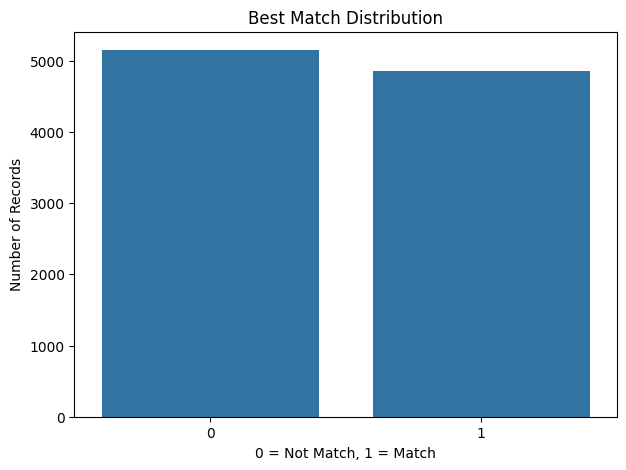

In [ ]:
print("Best Match Distribution:")

print(df["Best Match"].value_counts())

print("\nPercentage Distribution:")
print(
    df["Best Match"].value_counts(normalize=True) * 100
)
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Best Match")

plt.title("Best Match Distribution")
plt.xlabel("0 = Not Match, 1 = Match")
plt.ylabel("Number of Records")

plt.show()

In [ ]:
data = df[
    [
        "Resume",
        "Job Roles",
        "Job Description",
        "Best Match"
    ]
].copy()
print("Selected Columns:")
print(data.columns.tolist())

print("\nDataset Shape:", data.shape)

display(data.head())

Selected Columns:
['Resume', 'Job Roles', 'Job Description', 'Best Match']

Dataset Shape: (10000, 4)


,Resume,Job Roles,Job Description,Best Match
0,"Proficient in Injury Prevention, Motivation, N...",Fitness Coach,A Fitness Coach is responsible for helping cl...,0
1,"Proficient in Healthcare, Pharmacology, Medica...",Physician,"Diagnose and treat illnesses, prescribe medica...",0
2,"Proficient in Forecasting, Financial Modelling...",Financial Analyst,"As a Financial Analyst, you will be responsibl...",0
3,"Proficient in Budgeting, Supply Chain Optimiza...",Supply Chain Manager,A Supply Chain Manager oversees the entire sup...,1
4,"Proficient in Logistics, Negotiation, Procurem...",Supply Chain Manager,A Supply Chain Manager oversees the entire sup...,1


In [ ]:
print("Missing Values Before Cleaning:")
print(data.isnull().sum())
data = data.dropna(
    subset=[
        "Resume",
        "Job Roles",
        "Job Description",
        "Best Match"
    ]
).copy()
for column in ["Resume", "Job Roles", "Job Description"]:
    data = data[
        data[column].astype(str).str.strip() != ""
    ]
for column in ["Resume", "Job Roles", "Job Description"]:
    data = data[
        data[column].astype(str).str.strip() != ""
    ]


Missing Values Before Cleaning:
Resume             0
Job Roles          0
Job Description    0
Best Match         0
dtype: int64


In [ ]:
def clean_text(text):
      # Convert to string
    text = str(text)

    # Decode HTML entities
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove extra spaces and newlines
    text = re.sub(r"\s+", " ", text)

    # Remove leading and trailing spaces
    text = text.strip()

    return text
print("Text cleaning function created successfully!")

Text cleaning function created successfully!


In [ ]:
data["Resume_Clean"] = data["Resume"].apply(clean_text)
data["Job_Description_Clean"] = (
    data["Job Description"].apply(clean_text)
)
data["Job_Role_Clean"] = (
    data["Job Roles"].apply(clean_text)
)
print("Text preprocessing completed!")
display(
    data[
        [
            "Resume",
            "Resume_Clean",
            "Job Description",
            "Job_Description_Clean"
        ]
    ].head(3)
)

Text preprocessing completed!


,Resume,Resume_Clean,Job Description,Job_Description_Clean
0,"Proficient in Injury Prevention, Motivation, N...","proficient in injury prevention, motivation, n...",A Fitness Coach is responsible for helping cl...,a fitness coach is responsible for helping cli...
1,"Proficient in Healthcare, Pharmacology, Medica...","proficient in healthcare, pharmacology, medica...","Diagnose and treat illnesses, prescribe medica...","diagnose and treat illnesses, prescribe medica..."
2,"Proficient in Forecasting, Financial Modelling...","proficient in forecasting, financial modelling...","As a Financial Analyst, you will be responsibl...","as a financial analyst, you will be responsibl..."


In [ ]:
data["Job_Text"] = (
    data["Job_Role_Clean"] + " " +
    data["Job_Description_Clean"]
)
print("Combined Job Text:")
print(data["Job_Text"].iloc[0])

Combined Job Text:
fitness coach a fitness coach is responsible for helping clients achieve their fitness goals by designing and leading group or individual fitness programs. you will provide instruction on exercises, proper form, and injury prevention techniques, encouraging clients to push their limits while maintaining a focus on their well-being. the role requires a passion for health and fitness, a strong understanding of exercise physiology, and the ability to motivate and inspire others. you will also monitor clients’ progress and make adjustments to their fitness plans as needed to ensure continuous improvement.


In [ ]:
data["Combined_Text"] = (
    data["Resume_Clean"] + " " +
    data["Job_Text"]
)
print("Combined Text Created Successfully!")
display(
    data[
        ["Resume_Clean", "Job_Text", "Combined_Text"]
    ].head(3)
)

Combined Text Created Successfully!


,Resume_Clean,Job_Text,Combined_Text
0,"proficient in injury prevention, motivation, n...",fitness coach a fitness coach is responsible f...,"proficient in injury prevention, motivation, n..."
1,"proficient in healthcare, pharmacology, medica...","physician diagnose and treat illnesses, prescr...","proficient in healthcare, pharmacology, medica..."
2,"proficient in forecasting, financial modelling...","financial analyst as a financial analyst, you ...","proficient in forecasting, financial modelling..."


In [ ]:
data["Resume_Length"] = data["Resume_Clean"].str.len()

data["Job_Length"] = data["Job_Text"].str.len()

print("Resume Length Statistics:")
print(data["Resume_Length"].describe())

print("\nJob Description Length Statistics:")
print(data["Job_Length"].describe())

Resume Length Statistics:
count    10000.000000
mean       294.336000
std         15.177672
min        237.000000
25%        285.000000
50%        294.000000
75%        304.000000
max        363.000000
Name: Resume_Length, dtype: float64

Job Description Length Statistics:
count    10000.000000
mean       660.557200
std         49.519198
min        467.000000
25%        641.000000
50%        665.000000
75%        685.000000
max        786.000000
Name: Job_Length, dtype: float64


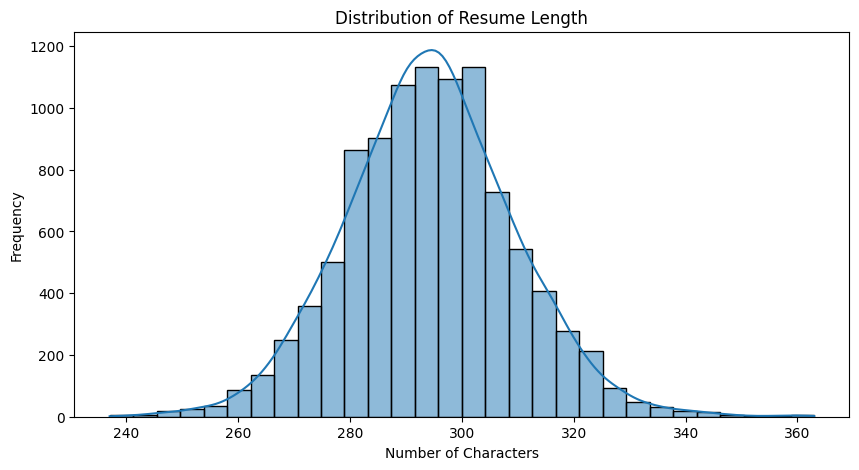

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data["Resume_Length"],
    bins=30,
    kde=True
)

plt.title("Distribution of Resume Length")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.show()

In [ ]:
data.to_csv(
    "preprocessed_resume_job_dataset.csv",
    index=False
)

print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


In [ ]:
role_counts = data["Job Roles"].value_counts()

print("Number of Unique Job Roles:")
print(data["Job Roles"].nunique())

print("\nTop 15 Job Roles:")
print(role_counts.head(15))

Number of Unique Job Roles:
51

Top 15 Job Roles:
Job Roles
Personal Trainer             226
Urban Planner                220
Biomedical Engineer          220
Construction Manager         215
Robotics Engineer            214
Mechanical Engineer          214
Operations Manager           209
Pilot                        209
Machine Learning Engineer    208
Web Developer                207
Financial Analyst            206
Creative Director            203
Environmental Scientist      203
Systems Analyst              203
Data Analyst                 202
Name: count, dtype: int64


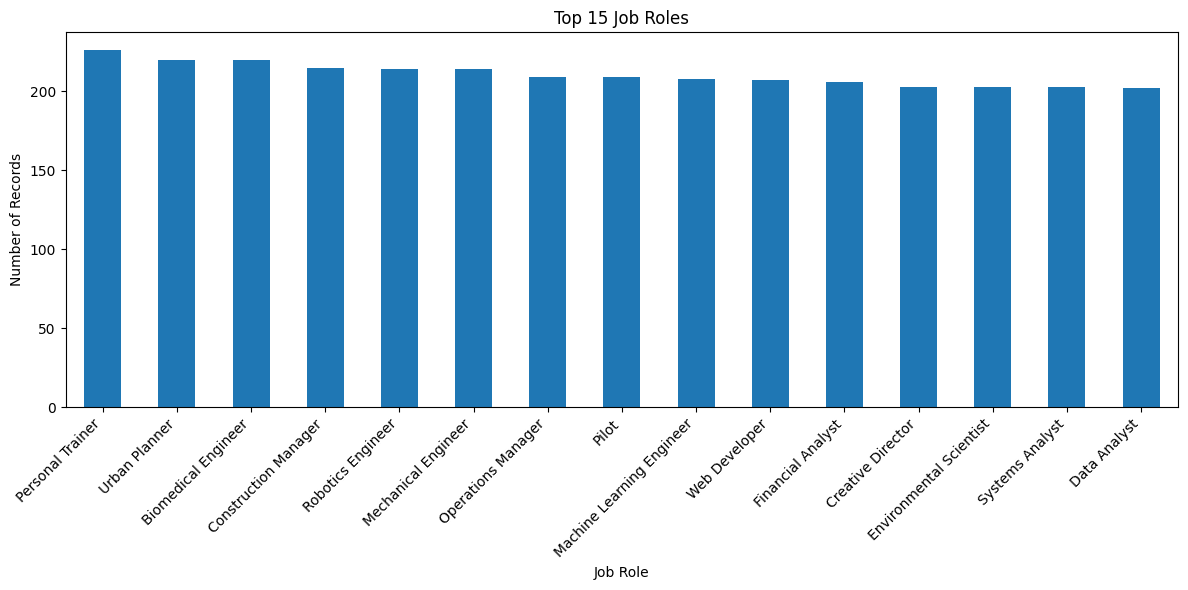

In [ ]:
plt.figure(figsize=(12, 6))

role_counts.head(15).plot(kind="bar")

plt.title("Top 15 Job Roles")
plt.xlabel("Job Role")
plt.ylabel("Number of Records")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
print("Match Distribution:")

print(data["Best Match"].value_counts())

print("\nMatch Percentage:")
print(
    data["Best Match"].value_counts(normalize=True) * 100
)

Match Distribution:
Best Match
0    5150
1    4850
Name: count, dtype: int64

Match Percentage:
Best Match
0    51.5
1    48.5
Name: proportion, dtype: float64


In [ ]:
role_match = (
    data.groupby("Job Roles")["Best Match"].mean() * 100
)
print("Match Percentage by Job Role:")
print(
    role_match.sort_values(ascending=False).head(15)
)

Match Percentage by Job Role:
Job Roles
Supply Chain Manager               58.291457
Financial Analyst                  58.252427
Psychologist                       55.497382
Chef                               54.950495
Customer Service Representative    54.838710
Urban Planner                      54.545455
Software Engineer                  54.314721
Content Writer                     54.069767
Pilot                              54.066986
Data Analyst                       53.960396
Lawyer                             53.763441
Cybersecurity Analyst              53.723404
Operations Manager                 53.588517
Business Analyst                   53.513514
Robotics Engineer                  53.271028
Name: Best Match, dtype: float64


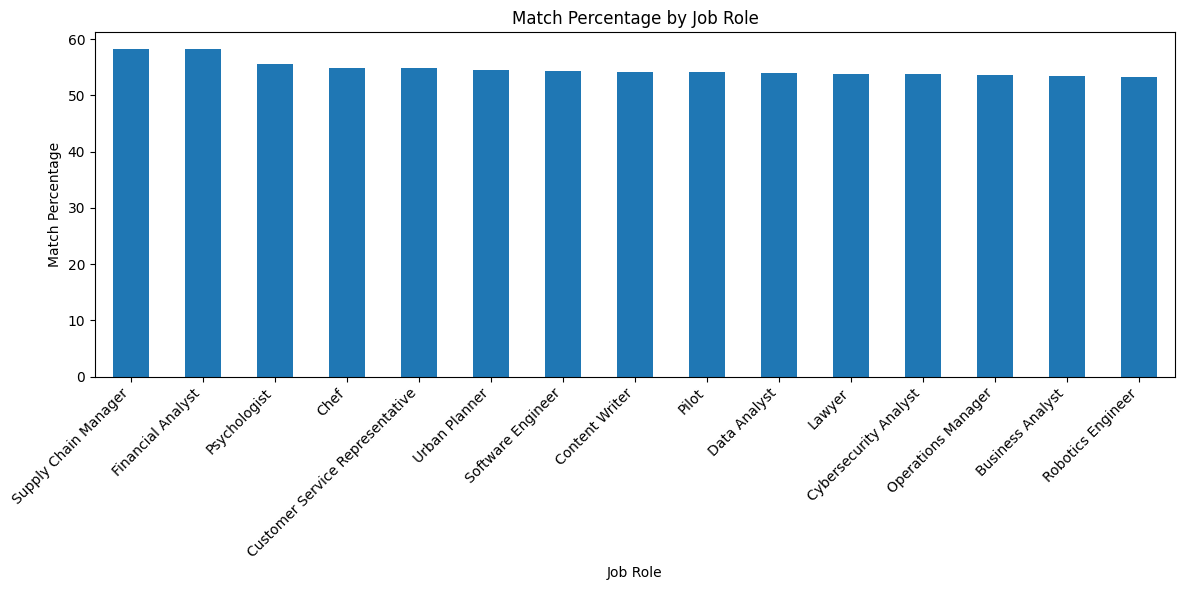

In [ ]:
plt.figure(figsize=(12, 6))

role_match.sort_values(
    ascending=False
).head(15).plot(kind="bar")

plt.title("Match Percentage by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Match Percentage")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

resume_text = " ".join(data["Resume_Clean"])
resume_words = re.findall(
    r"\b[a-zA-Z][a-zA-Z+#.]*\b",
    resume_text
)
resume_words = [
    word for word in resume_words
    if word not in ENGLISH_STOP_WORDS
    and len(word) > 1
]
resume_word_counts = Counter(resume_words)

print("Top 20 Resume Words:")
print(resume_word_counts.most_common(20))

Top 20 Resume Words:
[('holds', 20000), ('field', 10105), ('experience', 10101), ('proficient', 10000), ('level', 10000), ('degree', 10000), ('certifications', 10000), ('skilled', 10000), ('delivering', 10000), ('results', 10000), ('adapting', 10000), ('dynamic', 10000), ('environments', 10000), ('senior', 6806), ('certified', 4628), ('management', 4188), ('phd', 3369), ('masters', 3328), ('bachelors', 3303), ('mid', 3194)]


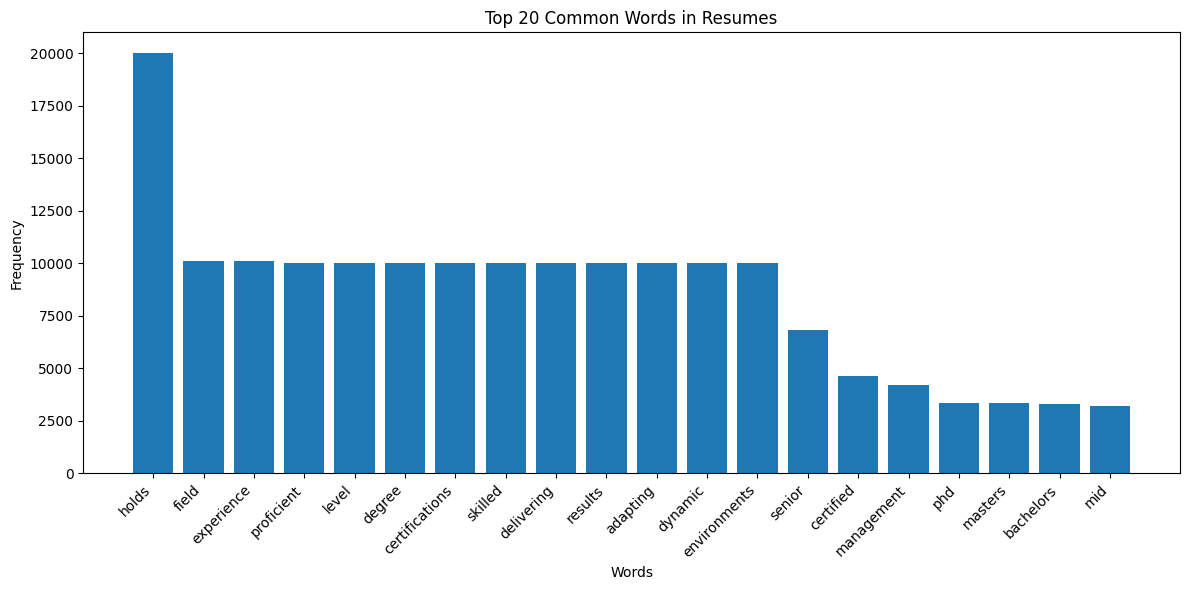

In [ ]:
common_words = resume_word_counts.most_common(20)

words = [x[0] for x in common_words]
counts = [x[1] for x in common_words]

plt.figure(figsize=(12, 6))

plt.bar(words, counts)

plt.title("Top 20 Common Words in Resumes")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
model_data = data.dropna(
    subset=[
        "Resume_Clean",
        "Job_Description_Clean",
        "Best Match"
    ]
).copy()

model_data["Best Match"] = pd.to_numeric(
    model_data["Best Match"],
    errors="coerce"
)
model_data = model_data[
    model_data["Best Match"].isin([0, 1])
].copy()
model_data["Best Match"] = (
    model_data["Best Match"].astype(int)
)
model_data["Combined_Text"] = (
    model_data["Resume_Clean"] + " " +
    model_data["Job_Role_Clean"] + " " +
    model_data["Job_Description_Clean"]
)

print("Model Dataset Shape:", model_data.shape)

print("\nTarget Distribution:")
print(model_data["Best Match"].value_counts())

Model Dataset Shape: (10000, 11)

Target Distribution:
Best Match
0    5150
1    4850
Name: count, dtype: int64


In [ ]:
X = model_data["Combined_Text"]

y = model_data["Best Match"]

print("Input Features:", X.shape)

print("Target Variable:", y.shape)

Input Features: (10000,)
Target Variable: (10000,)


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
groups = pd.factorize(
    model_data["Resume_Clean"]
)[0]
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)
train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Label Distribution:")
print(y_train.value_counts())

print("\nTesting Label Distribution:")
print(y_test.value_counts())

Training Records: 7999
Testing Records: 2001

Training Label Distribution:
Best Match
0    4142
1    3857
Name: count, dtype: int64

Testing Label Distribution:
Best Match
0    1008
1     993
Name: count, dtype: int64


In [ ]:
model_tfidf = TfidfVectorizer(
    max_features=20000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)
X_train_tfidf = model_tfidf.fit_transform(X_train)

X_test_tfidf = model_tfidf.transform(X_test)

print("TF-IDF Transformation Completed!")

print("Training TF-IDF Shape:", X_train_tfidf.shape)

print("Testing TF-IDF Shape:", X_test_tfidf.shape)

TF-IDF Transformation Completed!
Training TF-IDF Shape: (7999, 9004)
Testing TF-IDF Shape: (2001, 9004)


In [ ]:
model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [ ]:
y_pred = model.predict(X_test_tfidf)

y_prob = model.predict_proba(
    X_test_tfidf
)[:, 1]

print("Actual Labels:")
print(y_test.head(10).tolist())

print("\nPredicted Labels:")
print(y_pred[:10].tolist())

print("\nPredicted Match Probabilities:")
print(y_prob[:10])

Actual Labels:
[0, 1, 0, 1, 1, 0, 0, 1, 1, 0]

Predicted Labels:
[1, 1, 1, 0, 0, 0, 0, 1, 0, 0]

Predicted Match Probabilities:
[0.57205732 0.56972002 0.51958071 0.45279358 0.48031523 0.49219121
 0.48752041 0.57311075 0.4506372  0.4576055 ]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("MODEL PERFORMANCE")
print("----------------------------")

print("Accuracy:", round(accuracy * 100, 2), "%")

print("Precision:", round(precision * 100, 2), "%")

print("Recall:", round(recall * 100, 2), "%")

print("F1 Score:", round(f1 * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

MODEL PERFORMANCE
----------------------------
Accuracy: 53.62 %
Precision: 53.43 %
Recall: 50.96 %
F1 Score: 52.16 %

Classification Report:
              precision    recall  f1-score   support

           0       0.54      0.56      0.55      1008
           1       0.53      0.51      0.52       993

    accuracy                           0.54      2001
   macro avg       0.54      0.54      0.54      2001
weighted avg       0.54      0.54      0.54      2001



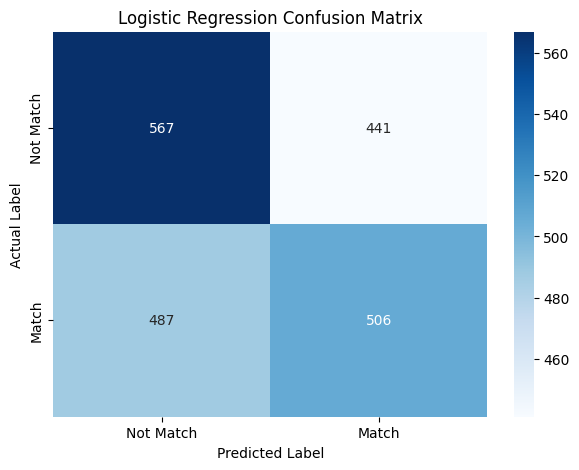

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Match", "Match"],
    yticklabels=["Not Match", "Match"]
)

plt.title("Logistic Regression Confusion Matrix")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
print("Actual Test Labels:")
print(y_test.value_counts())

print("\nPredicted Test Labels:")
print(pd.Series(y_pred).value_counts())

print("\nAverage Match Probability:")

print(round(y_prob.mean() * 100, 2), "%")

Actual Test Labels:
Best Match
0    1008
1     993
Name: count, dtype: int64

Predicted Test Labels:
0    1054
1     947
Name: count, dtype: int64

Average Match Probability:
48.06 %


In [ ]:
resume_vectors = model_tfidf.transform(
    model_data["Resume_Clean"]
)
job_vectors = model_tfidf.transform(
    model_data["Job_Role_Clean"] + " " +
    model_data["Job_Description_Clean"]
)
similarity_scores = np.asarray(
    resume_vectors.multiply(job_vectors).sum(axis=1)
).ravel()
model_data["Similarity_Score"] = similarity_scores

model_data["Similarity_Percentage"] = (
    similarity_scores * 100
)
print("Cosine Similarity Calculated!")
display(
    model_data[
        [
            "Job Roles",
            "Similarity_Score",
            "Similarity_Percentage",
            "Best Match"
        ]
    ].head(10)
)

Cosine Similarity Calculated!


,Job Roles,Similarity_Score,Similarity_Percentage,Best Match
0,Fitness Coach,0.051902,5.190171,0
1,Physician,0.061733,6.173259,0
2,Financial Analyst,0.114164,11.416417,0
3,Supply Chain Manager,0.129372,12.937192,1
4,Supply Chain Manager,0.108386,10.838629,1
5,Database Administrator,0.152739,15.273928,0
6,Architect,0.053084,5.308371,1
7,Operations Manager,0.034037,3.403738,0
8,Database Administrator,0.128178,12.817783,0
9,Architect,0.026384,2.638409,0


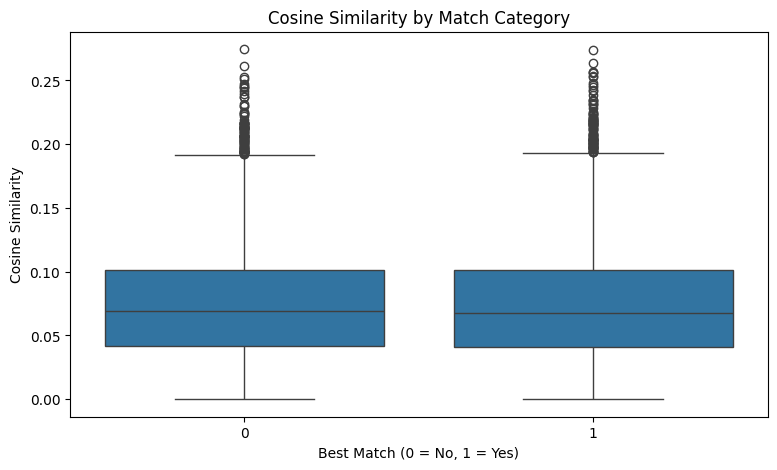

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=model_data,
    x="Best Match",
    y="Similarity_Score"
)

plt.title("Cosine Similarity by Match Category")
plt.xlabel("Best Match (0 = No, 1 = Yes)")
plt.ylabel("Cosine Similarity")

plt.show()

In [ ]:
skill_dictionary = [
    "python",
    "java",
    "javascript",
    "typescript",
    "c++",
    "c#",
    ".net",
    "sql",
    "mysql",
    "mongodb",
    "react",
    "node.js",
    "django",
    "flask",
    "html",
    "css",
    "machine learning",
    "deep learning",
    "artificial intelligence",
    "data analysis",
    "data visualization",
    "pandas",
    "numpy",
    "tensorflow",
    "pytorch",
    "scikit-learn",
    "power bi",
    "tableau",
    "excel",
    "aws",
    "azure",
    "docker",
    "kubernetes",
    "git",
    "linux",
    "communication",
    "project management",
    "statistics",
    "rest api",
    "spring boot"
]

print("Skill Dictionary Created!")
print("Total Skills:", len(skill_dictionary))

Skill Dictionary Created!
Total Skills: 40


In [ ]:
def extract_skills(text):
  text = clean_text(text)
  found_skills = []
  for skill in skill_dictionary:
      pattern = (r"(?<!\w)" +re.escape(skill) +r"(?!\w)")
      if re.search(pattern, text):
          found_skills.append(skill)

  return found_skills

print("Skill Extraction Function Created!")

Skill Extraction Function Created!


In [ ]:
def match_skills(resume, job_description):

    candidate_skills = extract_skills(resume)

    required_skills = extract_skills(job_description)

    matched_skills = list(
      set(candidate_skills) & set(required_skills)
    )
    missing_skills = list(
        set(required_skills) - set(candidate_skills)
    )
    if len(required_skills) > 0:
        skill_score = (
            len(matched_skills) /
            len(required_skills)
        ) * 100
    else:
        skill_score = 0
    return (
        sorted(candidate_skills),
        sorted(required_skills),
        sorted(matched_skills),
        sorted(missing_skills),
        skill_score
    )
print("Skill Matching Function Created!")

Skill Matching Function Created!


In [ ]:
sample_resume = """
Python developer with experience in Python,
SQL, Flask, Machine Learning and Pandas.
"""

sample_job = """
Looking for a Python developer with Python,
SQL, Flask, Machine Learning and TensorFlow.
"""
candidate, required, matched, missing, score = (
    match_skills(sample_resume, sample_job)
)
print("Candidate Skills:", candidate)

print("\nRequired Skills:", required)

Candidate Skills: ['flask', 'machine learning', 'pandas', 'python', 'sql']

Required Skills: ['flask', 'machine learning', 'python', 'sql', 'tensorflow']


In [ ]:
def predict_resume_match(resume, job_role, job_description):


    resume_clean = clean_text(resume)
    role_clean = clean_text(job_role)
    description_clean = clean_text(job_description)


    combined_text = (
        resume_clean + " " +
        role_clean + " " +
        description_clean
    )
    text_vector = model_tfidf.transform([combined_text])

    prediction = model.predict(text_vector)[0]

    probabilities = model.predict_proba(text_vector)[0]

    match_index = list(model.classes_).index(1)

    classifier_probability = (
        probabilities[match_index] * 100
    )
    resume_vector = model_tfidf.transform([resume_clean])

    job_vector = model_tfidf.transform([
        role_clean + " " + description_clean
    ])

    similarity_score = (
        cosine_similarity(
            resume_vector,
            job_vector
        )[0][0] * 100
    )
    candidate, required, matched, missing, skill_score = (
        match_skills(resume, job_description)
    )
    if len(required) > 0:
        overall_score = (
            0.60 * skill_score +
            0.40 * similarity_score
        )
    else:
        overall_score = similarity_score
    if overall_score >= 70:
        final_result = "Match"
    else:
        final_result = "Not Match"
    return {
        "Final Result": final_result,
        "Overall Match Score": round(overall_score, 2),
        "Skill Match Score": round(skill_score, 2),
        "Cosine Similarity": round(similarity_score, 2),
        "ML Classifier Prediction": (
            "Match" if prediction == 1 else "Not Match"
        ),
        "ML Classifier Probability": round(
            classifier_probability, 2
        ),
        "Candidate Skills": candidate,
        "Required Skills": required,
        "Matched Skills": matched,
        "Missing Skills": missing
    }

print("Updated prediction function created!")

Updated prediction function created!


In [ ]:
resume = """
Junior developer with knowledge of Python,
HTML, CSS and basic SQL.
Interested in learning Machine Learning.
"""

job_role = "Python Developer"

job_description = """
We are looking for a Python Developer with skills
in Python, SQL, Flask, Machine Learning and REST API.
"""

result = predict_resume_match(
    resume,
    job_role,
    job_description
)

for key, value in result.items():
    print(f"{key}: {value}")

Final Result: Not Match
Overall Match Score: 55.99
Skill Match Score: 60.0
Cosine Similarity: 49.97
ML Classifier Prediction: Not Match
ML Classifier Probability: 46.35
Candidate Skills: ['css', 'html', 'machine learning', 'python', 'sql']
Required Skills: ['flask', 'machine learning', 'python', 'rest api', 'sql']
Matched Skills: ['machine learning', 'python', 'sql']
Missing Skills: ['flask', 'rest api']


In [ ]:
resume = """
Python Developer with strong experience in Python,
SQL, Flask, Machine Learning and REST API development.

Skills include Python, SQL, Flask, Machine Learning,
REST API, Pandas, NumPy and Scikit-learn.

Developed applications using Python and Flask.
Designed SQL databases and implemented Machine Learning
algorithms. Developed REST APIs and integrated predictive
models into Python applications.
"""

job_role = "Python Developer"

job_description = """
We are looking for a Python Developer with skills
in Python, SQL, Flask, Machine Learning and REST API.
"""

result = predict_resume_match(
    resume,
    job_role,
    job_description
)

for key, value in result.items():
    print(f"{key}: {value}")

Final Result: Match
Overall Match Score: 90.93
Skill Match Score: 100.0
Cosine Similarity: 77.34
ML Classifier Prediction: Not Match
ML Classifier Probability: 47.65
Candidate Skills: ['flask', 'machine learning', 'numpy', 'pandas', 'python', 'rest api', 'scikit-learn', 'sql']
Required Skills: ['flask', 'machine learning', 'python', 'rest api', 'sql']
Matched Skills: ['flask', 'machine learning', 'python', 'rest api', 'sql']
Missing Skills: []


In [ ]:
resume = """
Graphic designer with experience in Photoshop,
Illustrator, logo design, video editing,
branding and creative design.
"""

job_role = "Python Developer"

job_description = """
We are looking for a Python Developer with skills
in Python, SQL, Flask, Machine Learning and REST API.
"""

result = predict_resume_match(
    resume,
    job_role,
    job_description
)

for key, value in result.items():
    print(f"{key}: {value}")

Final Result: Not Match
Overall Match Score: 0.0
Skill Match Score: 0.0
Cosine Similarity: 0.0
ML Classifier Prediction: Not Match
ML Classifier Probability: 42.69
Candidate Skills: []
Required Skills: ['flask', 'machine learning', 'python', 'rest api', 'sql']
Matched Skills: []
Missing Skills: ['flask', 'machine learning', 'python', 'rest api', 'sql']
